# Autoencoder for Anomaly Detection

This experiment investigates whether an autoencoder can detect unusual API log windows using reconstruction error. An autoencoder learns to reconstruct its input features. The hypothesis is that a model trained on representative normal observations may reconstruct unusual observations less accurately; this is not guaranteed.

## The Normality Assumption

Reconstruction-based anomaly detection commonly assumes that training data predominantly represent normal behaviour. In this project, ground-truth labels identifying normal and anomalous windows are unavailable, so a verified normal-only training set cannot be constructed directly.

## solution (we’ll manage, one way or another) : 

### Weak Supervision and Weak Labels

We use existing detectors to estimate which windows are likely to represent normal behaviour. This is a form of **weak supervision**: rules (like `B1 : Operational threshold rules for anomaly detection` & `B2: Classical Z-score`) and ML models (like `isolation forest`) provide noisy, potentially conflicting signals rather than verified labels.

- **B1 - Operational Thresholds:** flags windows violating at least one configured threshold.
- **B2 - Classical Z-score:** flags windows whose absolute Z-score exceeds > 3 for at least one of selected features (We will detail the selected features afterward)
- **Isolation Forest:** uses the existing model trained on the complete 2-week dataset.

Their outputs will be combined into weak labels, named `weak_pred`. These labels select candidate training observations (the the data assumed to be normal by these models); they are not ground truth -- they serve only to select the training set (X_train).


## 1. Setup - Load the Dataset and Existing Models

### Imports 

In [153]:
import warnings
warnings.filterwarnings('ignore')
import sys
from pathlib import Path

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report

from IPython.display import display

project_root = Path.cwd().parent 
sys.path.append(str(project_root))

from src.fink_api_anomaly_detection.models import Autoencoder, IsolationForestDetector

from src.fink_api_anomaly_detection.baselines import (
    ClassicalZScoreBaseline,
    OperationalThresholdBaseline,
    OperationalThresholds,
)

from src.fink_api_anomaly_detection.data.raw_logs import ls_log_files
from src.fink_api_anomaly_detection.preprocess.nginx_logs.access_logs import build_access_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.error_logs import build_error_dataframe
from src.fink_api_anomaly_detection.preprocess.nginx_logs.geo_logs import build_geo_dataframe
from src.fink_api_anomaly_detection.features.nginx_logs import build_temporal_features, build_feature_subsets


DATA_DIR = project_root / "data" / "nginx_history_logs"
print(f"Dataset directory: {DATA_DIR.resolve()}")

Dataset directory: /home/machter-l/fink-api-forecasting-anomaly-detection/data/nginx_history_logs


### Input data & temportal dataset constuction 

In [2]:
access_files = ls_log_files(DATA_DIR, "access-logs")
geo_files = ls_log_files(DATA_DIR, "geo-logs")
error_files = ls_log_files(DATA_DIR, "error-logs")

access_df = build_access_dataframe(access_files)
geo_df = build_geo_dataframe(geo_files)
errors_df = build_error_dataframe(error_files)

print(f"access_df.shape: {access_df.shape}")
print(f"geo_df.shape: {geo_df.shape}")
print(f"errors_df.shape: {errors_df.shape}")

features_df = build_temporal_features(access_df, geo_df, errors_df)
features_df = features_df[:-1]  # Remove last row to avoid 2026-10-17 00:00:00+00:00 last value no (no in 1-14 days) in features
print(f"Feature table shape: {features_df.shape}")
print(f"Time span: {features_df['timestamp'].min()} to {features_df['timestamp'].max()}")
display(features_df.head())
display(features_df.tail())

feature_sets = build_feature_subsets(features_df)


df = feature_sets["baseline_nginx_geography_endpoints"] # selected 20 features 
selected_features = df.columns
print("features:", selected_features)
print("df rows: ", df.shape[0])


access_df.shape: (1005103, 16)
geo_df.shape: (1005103, 6)
errors_df.shape: (833, 17)
Feature table shape: (4032, 24)
Time span: 2026-10-03 00:00:00+00:00 to 2026-10-16 23:55:00+00:00


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
0,2026-10-03 00:00:00+00:00,30,1,29,0,2,0.0,0.066667,6,1197413,...,0,3,0.600000,0,30,0,4,0.0,0.0,0.0
1,2026-10-03 00:05:00+00:00,36,0,36,0,0,0.0,0.0,4,3077416,...,0,3,0.472222,0,36,0,4,6.0,-0.066667,0.0
2,2026-10-03 00:10:00+00:00,353,1,352,0,0,0.0,0.0,9,83959825,...,0,4,0.929178,0,353,0,4,317.0,0.0,0.0
3,2026-10-03 00:15:00+00:00,363,1,362,0,0,0.0,0.0,9,100850864,...,0,4,0.851240,0,363,0,5,10.0,0.0,0.0
4,2026-10-03 00:20:00+00:00,327,2,325,1,4,0.003058,0.012232,8,72522424,...,1,3,0.935583,0,326,1,5,-36.0,0.012232,2.0


,timestamp,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,...,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,request_count_delta,http_5xx_rate_delta,nginx_error_count_delta
4027,2026-10-16 23:35:00+00:00,41,3,38,0,0,0.0,0.0,5,255428,...,0,3,0.536585,0,41,0,8,-47.0,0.0,0.0
4028,2026-10-16 23:40:00+00:00,44,2,42,0,0,0.0,0.0,10,608838,...,0,3,0.772727,0,44,0,6,3.0,0.0,0.0
4029,2026-10-16 23:45:00+00:00,79,4,75,0,0,0.0,0.0,8,1021306,...,0,4,0.772152,0,76,3,9,35.0,0.0,0.0
4030,2026-10-16 23:50:00+00:00,71,4,67,0,2,0.0,0.028169,10,371111,...,0,3,0.563380,0,71,0,10,-8.0,0.028169,1.0
4031,2026-10-16 23:55:00+00:00,67,4,63,0,0,0.0,0.0,10,1450850,...,0,4,0.462687,0,67,0,7,-4.0,-0.028169,-1.0


features: Index(['request_count', 'get_count', 'post_count', 'http_4xx_count',
       'http_5xx_count', 'http_4xx_rate', 'http_5xx_rate',
       'unique_client_count', 'bytes_sent_sum', 'nginx_error_count',
       'nginx_critical_count', 'nginx_timeout_count',
       'nginx_connection_reset_count', 'nginx_broken_pipe_count',
       'unique_country_count', 'top_country_share',
       'top_country_share_without_france', 'endpoint_api_count',
       'endpoint_unrecognized_count', 'unique_endpoint_count'],
      dtype='object')
df rows:  4032


## 2. Build weak labels (supposed anomalies/normal) from baselines & isof

### 2.1. Isolation Forest model trained on the full dataset

In [154]:
PATH_TO_ISOF_MODEL = str(project_root/"artifacts/isoforest_models/isoforest_train_1_14.joblib")
isof = IsolationForestDetector.load(PATH_TO_ISOF_MODEL)
print(isof.metadata_)

{'hyperparameters': {'bootstrap': False, 'contamination': 'auto', 'max_features': 1.0, 'max_samples': 'auto', 'n_estimators': 100, 'n_jobs': -1, 'random_state': 42, 'verbose': 0, 'warm_start': False}, 'n_features': 20, 'n_training_samples': 4032, 'training_date_utc': '2026-10-28T09:32:24.900406+00:00'}


predictions from isof (-1 : anomaly , 1 : normal):

In [4]:
isof_predictions = isof.predict(df)
isof_predictions = isof_predictions.map(
    {
        -1: 1, # True (anomaly)
         1: 0, # False (normal)
    }
).rename("isof_is_anomaly")
isof_predictions.value_counts(normalize=True)*100

isof_is_anomaly
0    94.84127
1     5.15873
Name: proportion, dtype: float64

Isof predict a portion of 5,16% as anomalies.
 
**Note:** these predictions are in-sample because the model was trained on the same dataset.

### 2.2. B1 - Thresholds rules

Baseline 1 flags **high 5xx/4xx rates, unusually high request volume, and high Nginx error counts**. The score is the number of rules triggered in a window; any positive score (>0) is an anomaly.


Each upper threshold is computed from the full the temporal data (days 1-14) as mean + 2 population standard deviations. Rate thresholds are capped at 1.0, their maximum possible value.

In [5]:
sigma_multiplier = 2.0

def mean_plus_sigma(values):
    return float(values.mean() + sigma_multiplier * values.std(ddof=0))

threshold_values = {
    "http_5xx_rate_max": min(1.0, mean_plus_sigma(df["http_5xx_rate"])),
    "http_4xx_rate_max": min(1.0, mean_plus_sigma(df["http_4xx_rate"])),
    "request_count_max": mean_plus_sigma(df["request_count"]),
    "nginx_error_count_max": mean_plus_sigma(df["nginx_error_count"]),
}
thresholds = OperationalThresholds(**threshold_values)
b1 = OperationalThresholdBaseline(thresholds)

display(pd.DataFrame([threshold_values], index=[f"mean + {sigma_multiplier:g} sigma"]))

,http_5xx_rate_max,http_4xx_rate_max,request_count_max,nginx_error_count_max
mean + 2 sigma,0.115035,0.165176,1030.743761,1.628822


b1 predictions (True : anomaly , false : normal):

In [6]:
b1_predictions = b1.predict(df)
b1_predictions =  b1_predictions["is_anomaly"].map({
        True: 1, # True (anomaly)
         False: 0, # False (normal)
    }).rename("b1_is_anomaly")
b1_predictions.value_counts(normalize=True) * 100

b1_is_anomaly
0    91.542659
1     8.457341
Name: proportion, dtype: float64

B1 predict 8,45% as anomalies

### 2.3. B2 - Classical Z-score

Apply the classical Z-score baseline independently to the same four features used by B1:
`request_count` `http_5xx_rate` `http_4xx_rate` `nginx_error_count`

A feature flags a window when its absolute Z-score is strictly greater than 3. The final B2 prediction flags a window if **at least one** of the four features flags it. The result is a Boolean `b2_is_anomaly`  like the B1 and Isolation Forest predictions.

In [7]:
b2_features = ["request_count", "http_5xx_rate", "http_4xx_rate", "nginx_error_count"]

b2_predictions_by_feature = pd.concat(
    [
        ClassicalZScoreBaseline(feature=feature, threshold=3.0)
        .fit(df)
        .predict(df)["is_anomaly"]
        .reset_index(drop=True)
        .rename(feature)
        for feature in b2_features
    ],
    axis=1,
)

b2_predictions = b2_predictions_by_feature.any(axis=1).map({
        True: 1, # True (anomaly)
         False: 0, # False (normal)
    }).rename("b2_is_anomaly")

b2_predictions.value_counts(normalize=True) * 100

b2_is_anomaly
0    95.486111
1     4.513889
Name: proportion, dtype: float64

b2 predict 4,5% as anomalies

## 3. Construct Weak Labels (from models anomaly votes)

### 3.1. Combine Detector Predictions & vote 

For each window, define: Vote(x) = B1_pred(x) + B2_pred(x) + IsoF_pred(x)

Each detector contributes `1` for an anomaly and `0` otherwise. The number of anomaly votes ranges from zero to three.

In [8]:
detector_predictions = pd.concat(
    [
        isof_predictions.reset_index(drop=True),
        b1_predictions.reset_index(drop=True),
        b2_predictions.reset_index(drop=True),
    ],
    axis=1,
)

anomaly_votes = detector_predictions.sum(axis=1).astype("int8").rename("anomaly_votes")
print(anomaly_votes.value_counts().sort_index())
print("total windows: ", len(anomaly_votes))

anomaly_votes
0    3662
1     125
2     129
3     116
Name: count, dtype: int64
total windows:  4032


### 3.2. Define the Weak-Label Categories

| Anomaly votes | Weak-label category | Interpretation |
|---:|---|---|
| 0 | `supposed_normal` | All three detectors consider the window normal |
| 1 | `uncertain` | One detector flags the window |
| 2 or 3 | `supposed_anomaly` | At least two detectors flag the window |


In [9]:
weak_pred = pd.Series(
    pd.Categorical(
        np.select(
            [anomaly_votes.eq(0), anomaly_votes.ge(2)],
            ["supposed_normal", "supposed_anomaly"],
            default="uncertain",
        ),
        categories=["supposed_normal", "uncertain", "supposed_anomaly"],
        ordered=True,
    ),
    index=anomaly_votes.index,
    name="weak_pred",
)

weak_pred.value_counts().reindex(
    ["supposed_normal", "uncertain", "supposed_anomaly"], fill_value=0
)

weak_pred
supposed_normal     3662
uncertain            125
supposed_anomaly     245
Name: count, dtype: int64

**Most windows (3662/4032; 90.8%) received no anomaly votes**. A total of **125/4032 windows (3.1%)** received **one vote** and are **classified as uncertain**, while **245/4032 (6.1%)** received at **least two votes** and are classified as **supposed anomalies**. These are weak labels , not verified anomalies.

### 3.3. integrate the Weak Labels into df 


In [10]:
df["weak_pred"] = weak_pred.to_numpy()
print("df.features (20 feature + weak pred): ", df.columns.to_list())
print("df.shape : ", df.shape)
df.head()


df.features (20 feature + weak pred):  ['request_count', 'get_count', 'post_count', 'http_4xx_count', 'http_5xx_count', 'http_4xx_rate', 'http_5xx_rate', 'unique_client_count', 'bytes_sent_sum', 'nginx_error_count', 'nginx_critical_count', 'nginx_timeout_count', 'nginx_connection_reset_count', 'nginx_broken_pipe_count', 'unique_country_count', 'top_country_share', 'top_country_share_without_france', 'endpoint_api_count', 'endpoint_unrecognized_count', 'unique_endpoint_count', 'weak_pred']
df.shape :  (4032, 21)


,request_count,get_count,post_count,http_4xx_count,http_5xx_count,http_4xx_rate,http_5xx_rate,unique_client_count,bytes_sent_sum,nginx_error_count,...,nginx_timeout_count,nginx_connection_reset_count,nginx_broken_pipe_count,unique_country_count,top_country_share,top_country_share_without_france,endpoint_api_count,endpoint_unrecognized_count,unique_endpoint_count,weak_pred
0,30,1,29,0,2,0.0,0.066667,6,1197413,0,...,0,0,0,3,0.600000,0,30,0,4,supposed_normal
1,36,0,36,0,0,0.0,0.0,4,3077416,0,...,0,0,0,3,0.472222,0,36,0,4,supposed_normal
2,353,1,352,0,0,0.0,0.0,9,83959825,0,...,0,0,0,4,0.929178,0,353,0,4,supposed_normal
3,363,1,362,0,0,0.0,0.0,9,100850864,0,...,0,0,0,4,0.851240,0,363,0,5,supposed_normal
4,327,2,325,1,4,0.003058,0.012232,8,72522424,2,...,0,1,1,3,0.935583,0,326,1,5,supposed_anomaly


## 4. Construct the Autoencoder Training Data

### 4.1. Select Candidate Normal Windows

Train the autoencoder only on windows labeled `supposed_normal`. Keep `uncertain` and `supposed_anomaly` windows together as a held-out set for later inspection; these are weak labels, not verified ground truth.

In [11]:
feature_columns = [f for f in df.columns if f !="weak_pred"]

X = df.loc[:, feature_columns].copy()
y_weak = df["weak_pred"].copy() # y , but it is not ground truth (just weak pred from refs models)

normal_mask = y_weak.eq("supposed_normal")

X_train = X.loc[normal_mask].copy() # X train contrain supposed normal windows 
X_test = X.loc[~normal_mask].copy() # X test contain uncertain and anoumalies
y_test_weak = y_weak.loc[~normal_mask].copy() # additionnaly for example to calculate estimated(weak) precision/recall/..

print(f"Features used: {len(feature_columns)}")
print(f"Candidate-normal training windows: {len(X_train)} ({len(X_train) / len(df):.1%})")
print(f"test set uncertain/anomaly windows: {len(X_test)} ({len(X_test) / len(df):.1%})")

Features used: 20
Candidate-normal training windows: 3662 (90.8%)
test set uncertain/anomaly windows: 370 (9.2%)


## 4.2. input data for the Autoencoder

In [12]:
print(f"Input (normal data) shape: {X_train.shape}")
print("Feature order:", X_train.columns.to_list())

Input (normal data) shape: (3662, 20)
Feature order: ['request_count', 'get_count', 'post_count', 'http_4xx_count', 'http_5xx_count', 'http_4xx_rate', 'http_5xx_rate', 'unique_client_count', 'bytes_sent_sum', 'nginx_error_count', 'nginx_critical_count', 'nginx_timeout_count', 'nginx_connection_reset_count', 'nginx_broken_pipe_count', 'unique_country_count', 'top_country_share', 'top_country_share_without_france', 'endpoint_api_count', 'endpoint_unrecognized_count', 'unique_endpoint_count']


## 5. Train the Autoencoder

The dense autoencoder class implemented through general class  in `src/fink_api_anomaly_detection/models/ae.py`


### Training

The autoencoder takes 20 input features and compresses them through two ReLU encoder layers of 64 and 16 units into an 8-unit ReLU code. The decoder then expands this representation through ReLU layers of 16 and 64 units, before producing a linear output of 20 reconstructed features

`Autoencoder.fit` fits a `StandardScaler` on the training portion of candidate-normal windows only. It applies that fitted scaler to validation and inference data

For an input vector x, the autoencoder produces a reconstruction ~x. Train it to minimise the mean squared reconstruction error. The model is trained on candidate-normal windows selected by weak labels; those weak labels are not ground-truth targets.



In [ ]:
ae = Autoencoder(
    code_dim=8, hidden_dims=(64, 16), optimizer="adam",
    epochs=100, batch_size=64, patience=5,
    random_state=42, checkpoint_path=str(project_root / "artifacts/ae/checkpoints/best.weights.h5"
)

ae.fit(X_train) # input=target= X_train
ae.model.summary()

Model: "anomalydetection"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_1 (Dense)               │ (None, 64)             │         1,344 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_2 (Dense)               │ (None, 16)             │         1,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_1 (Dense)               │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_2 (Dense)               │ (None, 64)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 20)             │         1,300 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,158 (59.21 KB)

 Trainable params: 5,052 (19.73 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 10,106 (39.48 KB)

In [36]:
history = ae.history_.history

best_epoch = history["val_loss"].index(min(history["val_loss"])) + 1
best_val_loss = min(history["val_loss"])

print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.6f}")

Best epoch: 91
Best validation loss: 0.060079


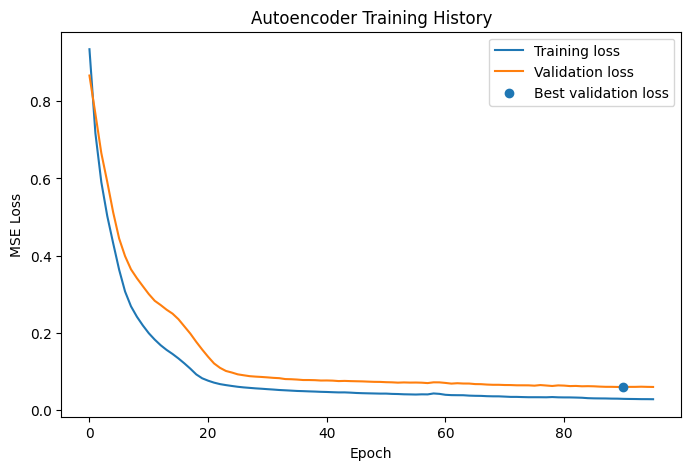

In [37]:
plt.figure(figsize=(8, 5))
plt.plot(history["loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.scatter(best_epoch - 1, best_val_loss, label="Best validation loss", zorder=3)
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Autoencoder Training History")
plt.legend()
plt.show()

## 6. Reconstruction Error and Anomaly Threshold

### 6.1. Calculate Reconstruction Errors


In [44]:
train_scores = ae.decision_function(X_train)
test_scores = ae.decision_function(X_test)

ae_train_results = pd.DataFrame(
    {
        "timestamp": features_df.loc[train_scores.index, "timestamp"],
        "reconstruction_error": train_scores,
    },
    index=train_scores.index,
)

ae_test_results = pd.DataFrame(
    {
        "timestamp": features_df.loc[test_scores.index, "timestamp"],
        "weak_pred": y_test_weak.loc[test_scores.index],
        "reconstruction_error": test_scores,
    },
    index=test_scores.index,
)

print(f"Scored candidate-normal training windows: {len(ae_train_results)} / {len(X)}")
display(ae_train_results.describe())
print(f"Scored test uncertain/anomalies (weak-label) windows: {len(ae_test_results)} / {len(X)}")
display(ae_test_results.describe())

Scored candidate-normal training windows: 3662 / 4032


,reconstruction_error
count,3662.000000
mean,0.035293
std,0.108772
min,0.000885
25%,0.004331
50%,0.009781
75%,0.025692
max,3.115732


Scored test uncertain/anomalies (weak-label) windows: 370 / 4032


,reconstruction_error
count,370.000000
mean,1980.587277
std,16745.260194
min,0.053047
25%,0.522341
50%,1.571981
75%,7.502082
max,203652.143273


**Note**: The reconstruction errors show a clear **difference between the candidate-normal training set and the test set containing uncertain and suspected anomalous observations**.

- **Training set (3662 observations):** The median reconstruction error is very low (0.0098), and 75% of the errors are below 0.0257. This indicates that the autoencoder has learned to reconstruct the candidate-normal traffic patterns effectively.
- **Test set (370 observations):** The median reconstruction error is significantly higher (1.5720), with 75% of the errors below 7.5021. This suggests that many test observations exhibit patterns that differ from those learned during training.
- **Extreme values:** The test set contains particularly large reconstruction errors, reaching 203652.14 (I suspect the 16/10/2026 at ~12:00-13h00 PM, based on an OpenVAS scan.), let see this:

In [56]:
display(
    ae_test_results.loc[
        ae_test_results["timestamp"].between(pd.Timestamp("2026-10-16 12:00:00+00:00"),pd.Timestamp("2026-10-16 13:00:00+00:00"),inclusive="left")
    ]
)

,timestamp,weak_pred,reconstruction_error
3888,2026-10-16 12:00:00+00:00,supposed_anomaly,1170.134514
3889,2026-10-16 12:05:00+00:00,supposed_anomaly,98012.061928
3890,2026-10-16 12:10:00+00:00,supposed_anomaly,203652.143273
3891,2026-10-16 12:15:00+00:00,supposed_anomaly,56625.082256
3892,2026-10-16 12:20:00+00:00,supposed_anomaly,57973.883360
3893,2026-10-16 12:25:00+00:00,supposed_anomaly,189677.025039
3894,2026-10-16 12:30:00+00:00,supposed_anomaly,104848.845837
3895,2026-10-16 12:35:00+00:00,supposed_anomaly,17325.148213


Indeed, a major reconstruction error (on the order of 10k) -- It’s a good thing the model is starting to understand that this scanning by bots isn’t normal.



Overall, these results suggest that the autoencoder captures the reconstruction patterns of candidate-normal traffic and assigns substantially higher errors to many uncertain and suspected anomalous observations.

The next step is to experiment with different reconstruction error thresholds to determine how effectively the model separates normal and suspected anomalous observations.

First, we exclude uncertain observations and calculate the reconstruction error for the remaining dataset:


In [71]:
uncertain_mask = y_weak.eq("uncertain")

reconstructions_error = ae.decision_function(X.loc[~uncertain_mask])

y_weak_boolean = y_weak[~uncertain_mask].map({"supposed_anomaly": True, "supposed_normal":False})

recons_df = pd.DataFrame({ "error": reconstructions_error, "y_weak":y_weak_boolean})
display(recons_df.sort_values("error",ascending=False).head(20))
print(recons_df.shape)

,error,y_weak
3890,203652.143273,True
3893,189677.025039,True
3894,104848.845837,True
3889,98012.061928,True
3892,57973.883360,True
3891,56625.082256,True
3895,17325.148213,True
3888,1170.134514,True
1700,261.652094,True
2826,159.923400,True


(3907, 2)


The `y_weak` column contains the reference labels converted into Boolean values:

- `True`: supposed anomaly
- `False`: supposed normal

#### Test different threshold values

we test several thresholds values based on the quantiles of the reconstruction-error distribution.

For each threshold, we classify observations and calculate weak-label-based evaluation metrics :  accuracy, macro-averaged precision, and macro-averaged recall.

In [112]:
def thresholdTuning(df, iterations):

    thresh_df = {
        'threshold': [],
        'accuracy': [],
        'precision': [],
        'recall': []
    }

    for i in range(iterations):
        thresh_value = df['error'].quantile(i/iterations)
        preds = df['error'] > thresh_value
        cr = classification_report(df['y_weak'], preds, output_dict=True)
        acc = cr['accuracy']
        prec = cr['macro avg']['precision']
        rc = cr['macro avg']['recall']
        

        thresh_df['threshold'].append(thresh_value)
        thresh_df['accuracy'].append(acc)
        thresh_df['precision'].append(prec)
        thresh_df['recall'].append(rc)

        print(f"Threshold: {thresh_value:.4f}\tAccuracy: {acc:.3f}\t\tPrecision: {prec:.3f}\tRecall Score: {rc:.3f}")

    return pd.DataFrame(thresh_df)

thresh_df = thresholdTuning(recons_df, 14)

Threshold: 0.0009	Accuracy: 0.063		Precision: 0.531	Recall Score: 0.500
Threshold: 0.0021	Accuracy: 0.134		Precision: 0.534	Recall Score: 0.538
Threshold: 0.0030	Accuracy: 0.206		Precision: 0.537	Recall Score: 0.576
Threshold: 0.0040	Accuracy: 0.277		Precision: 0.540	Recall Score: 0.614
Threshold: 0.0050	Accuracy: 0.349		Precision: 0.544	Recall Score: 0.653
Threshold: 0.0064	Accuracy: 0.420		Precision: 0.549	Recall Score: 0.691
Threshold: 0.0083	Accuracy: 0.491		Precision: 0.555	Recall Score: 0.729
Threshold: 0.0112	Accuracy: 0.563		Precision: 0.563	Recall Score: 0.767
Threshold: 0.0148	Accuracy: 0.634		Precision: 0.573	Recall Score: 0.805
Threshold: 0.0192	Accuracy: 0.706		Precision: 0.588	Recall Score: 0.843
Threshold: 0.0274	Accuracy: 0.777		Precision: 0.610	Recall Score: 0.881
Threshold: 0.0424	Accuracy: 0.848		Precision: 0.646	Recall Score: 0.919
Threshold: 0.0857	Accuracy: 0.920		Precision: 0.720	Recall Score: 0.957
Threshold: 0.3608	Accuracy: 0.986		Precision: 0.918	Recall Score

Among the tested thresholds, **0.3608** is good based on weak labels because it achieves the highest accuracy, precision, and recall. we can also define the anomaly thresholds (from all dataset) using the upper IQR bound (Q3 + 1.5 × IQR) & Q-95: 

In [148]:

errors = ae.decision_function(X)

Q1 = errors.quantile(0.25)
Q3 = errors.quantile(0.75)
IQR = Q3 - Q1

threshold_iqr = Q3 + 1.5 * IQR

print(f"IQR threshold: {threshold_iqr:.6f}")
print(f"Q 95% threshold : {errors.quantile(0.95)}")

IQR threshold: 0.093177
Q 95% threshold : 1.3492002806320993


### 6.2. Predictions based on thresholds 

for overall dataset (including supposed uncertain class) :

In [147]:
predictions_th_1 = ae.predict(X, threshold=0.3608) # from weak-labels eval
print(predictions_th_1.value_counts(normalize=True)*100)

print("\n ")
predictions_th_2 = ae.predict(X, threshold=0.093177) # threshold 2 = 0.093177 (from IQR)
print(predictions_th_2.value_counts(normalize=True)*100)

print("\n ")
predictions_th_3 = ae.predict(X, threshold=1.3492002806320993) # threshold 3 =  1.3492002806320993 (from Q 95)
print(predictions_th_3.value_counts(normalize=True)*100)


is_anomaly
False    91.443452
True      8.556548
Name: proportion, dtype: float64

 
is_anomaly
False    79.712302
True     20.287698
Name: proportion, dtype: float64

 
is_anomaly
False    86.780754
True     13.219246
Name: proportion, dtype: float64


As the threshold increases, fewer observations are classified as anomalies, which reduces the risk of false positives but may cause some anomalies to be missed. Therefore, the threshold should be chosen according to the desired balance between detecting as many anomalies as possible and limiting false alarms. 

## Analysis

The autoencoder shows a strong agreement with the weak labels. several thresholds values can considered: **0.3608**, selected through weak-label calibration, and others threshold , obtained using the IQR and Quantiles method . The first threshold provides the strongest agreement with the weak labels among the tested values, while the second offers a more data-driven alternative based on the distribution of reconstruction errors. We will retain  for the moment **0.3608** as the current threshold.

However, unsupervised log anomaly detection has several limitations:

- No ground-truth labels are available to verify actual detection performance.
- Weak labels may contain errors, and existing detectors may have correlated errors.

Despite these limitations, we will proceed with this autoencoder and the selected threshold for now, and save the model to disk:

In [150]:
ae.save(project_root / "artifacts/ae/")


## References

1. Ratner et al. (2016), *Data Programming: Creating Large Training Sets, Quickly*. [Paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC5985238/)
2. *RCA: A Deep Collaborative Autoencoder Approach for Anomaly Detection* (2022). [Paper](https://pmc.ncbi.nlm.nih.gov/articles/PMC9036495/)